In [ ]:
import numpy as np

# Modul sis (ako nije instaliran, npr. u Google Colab-u, instalira se automatski)
try:
    import sis
except ModuleNotFoundError:
    %pip install -q git+https://github.com/esokic/sis.git
    import sis

sis.FORMAT = "JUPYTER"    # prikaz grafika prilagodjen interaktivnom radu

In [2]:
# =========================================================
# Kod 8.1 - Koeficijenti Fourierovog reda trigonometrijskog
#           polinoma pomocu DFT
# =========================================================

In [3]:
# parametri
w0  = np.pi            # osnovna ugaona ucestanost
T   = 2 * np.pi / w0   # period = 2
N   = 10               # broj uzoraka (N > 2M, gdje je M=2)
M   = 2                # najvisi harmonik u polinomu

# vremenska baza uzorkovanja: N ravnomjerno rasporedjenih
# tacaka na periodu [0, T)
t1 = np.arange(N) * T / N

# uzorkovana funkcija
x1 = 1 + 2 * np.sin(2 * w0 * t1) - np.cos(w0 * t1)

# FFT uzorkovane funkcije
X = sis.fft(x1)

# koeficijenti Fourierovog reda:
# C0 = X(0)/N,  Cm = X(m)/N,  C-m = X(N-m)/N,  m = 1..M
Ck = {}
Ck[0] = X[0] / N
for m in range(1, M + 1):
    Ck[m]  = X[m] / N
    Ck[-m] = X[N - m] / N

print("Koeficijenti Fourierovog reda dobijeni DFT-om:")
print(f"  C[ 0] = {Ck[ 0]:.2f}  (analiticki:  1+0j)")
print(f"  C[ 1] = {Ck[ 1]:.2f}  (analiticki: -0.5+0j)")
print(f"  C[-1] = {Ck[-1]:.2f}  (analiticki: -0.5+0j)")
print(f"  C[ 2] = {Ck[ 2]:.2f}  (analiticki:  0-1j)")
print(f"  C[-2] = {Ck[-2]:.2f}  (analiticki:  0+1j)")

Koeficijenti Fourierovog reda dobijeni DFT-om:
  C[ 0] = 1.00+0.00j  (analiticki:  1+0j)
  C[ 1] = -0.50+0.00j  (analiticki: -0.5+0j)
  C[-1] = -0.50-0.00j  (analiticki: -0.5+0j)
  C[ 2] = -0.00-1.00j  (analiticki:  0-1j)
  C[-2] = -0.00+1.00j  (analiticki:  0+1j)


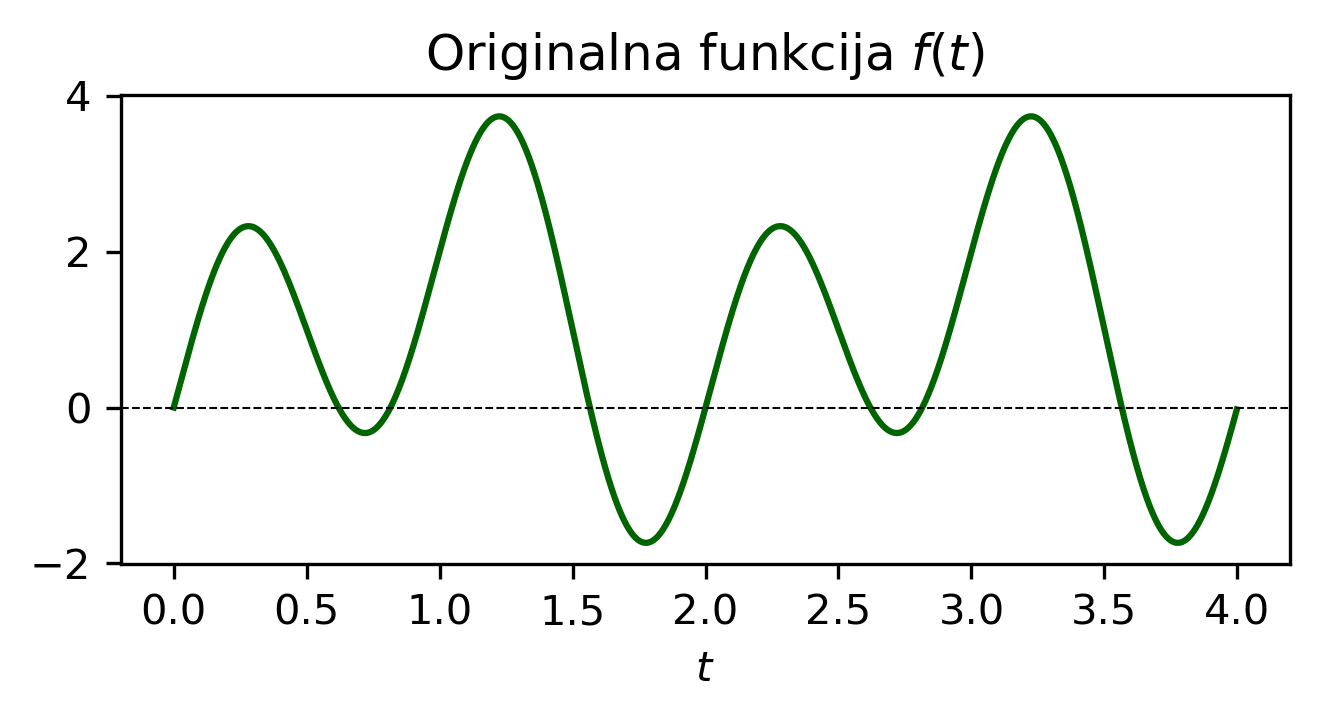

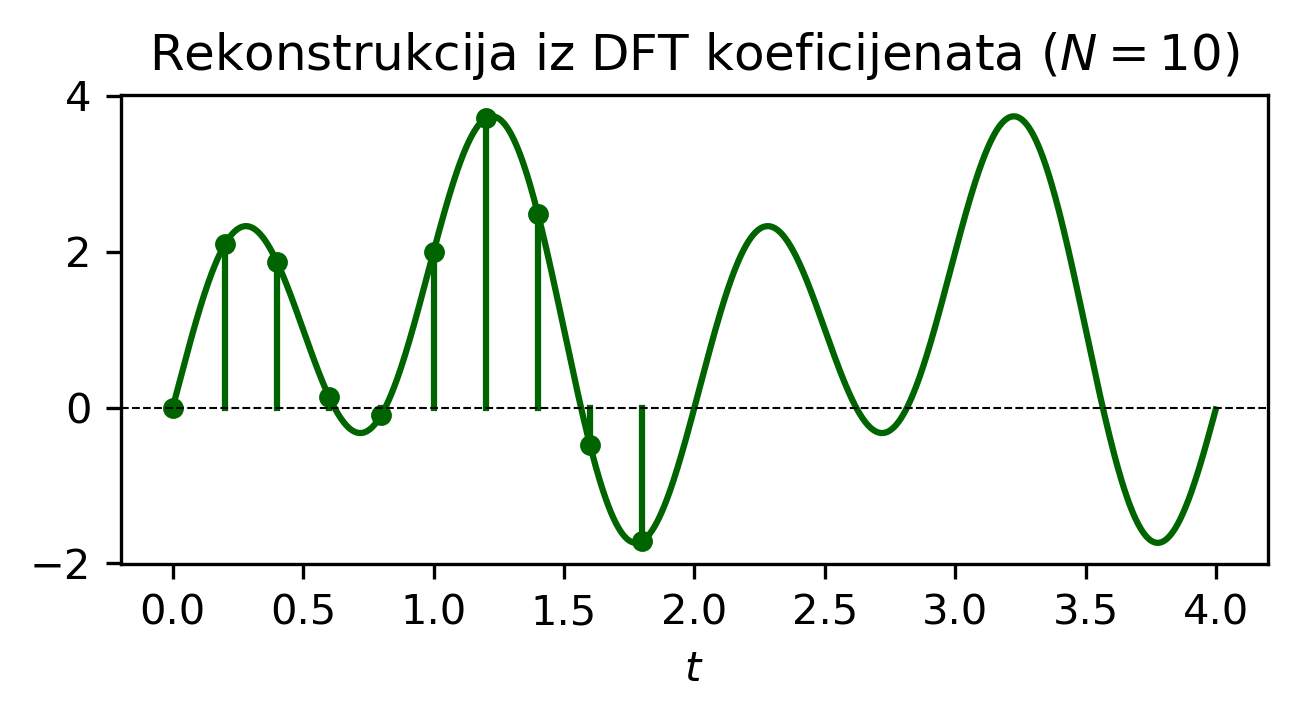

In [4]:
# graficki prikaz: originalna vs. rekonstruirana funkcija
t = np.arange(0, 2* T, T / 1000)

# originalna funkcija
x = 1 + 2 * np.sin(2 * w0 * t) - np.cos(w0 * t)

# rekonstrukcija iz DFT koeficijenata
apr = Ck[0] * np.ones(len(t))
for m in range(1, M + 1):
    apr = apr + Ck[m] * np.exp(1j * m * w0 * t) \
              + Ck[-m] * np.exp(-1j * m * w0 * t)

sis.dijagram(t, x, 
             naslov='Originalna funkcija $f(t)$')

sis.dijagram(serije=[dict(t=t, x=np.real(apr)), 
                     dict(t=t1, x=x1, tip='uzorci', marker = 'o')],
             naslov=f'Rekonstrukcija iz DFT koeficijenata ($N={N}$)') 

In [5]:
# =========================================================
# Kod 8.2 - Priblizno odredjivanje koeficijenata Fourierovog
#           reda periodicke funkcije pomocu DFT
# =========================================================

In [6]:
# parametri
T0  = 8       # period funkcije
N   = 12      # broj uzoraka
T1  = T0 / N  # period uzorkovanja
w0  = 2 * np.pi / T0

def trapez(t, T0):
    """Trapezoidna periodicna funkcija (definirana analiticki)."""
    t = t % T0
    x = np.zeros(len(t))
    for i, ti in enumerate(t):
        if   0 <= ti < 1: x[i] = ti
        elif 1 <= ti < 3: x[i] = 1
        elif 3 <= ti < 5: x[i] = 1 - (ti - 3)
        elif 5 <= ti < 7: x[i] = -1
        elif 7 <= ti < 8: x[i] = (ti - 7) - 1
    return x

# koeficijenti Cm iz definicione relacije
ts_def = 0.0001
t_def  = np.arange(0, T0, ts_def)
x_def  = trapez(t_def, T0)

m_max = 15
m_os  = np.arange(-m_max, m_max + 1)
C_def = np.zeros(len(m_os), dtype=complex)
for i, m in enumerate(m_os):
    C_def[i] = ts_def / T0 * np.sum(
        x_def * np.exp(-1j * m * w0 * t_def))

# DFT koeficijenti Cm ~= X(m)/N, periodicni po N
t1 = np.arange(N) * T1
x1 = trapez(t1, T0)
X  = sis.fft(x1)
C_dft = np.array([X[m % N] / N for m in m_os])

# ispis koeficijenata za m = 0, 1, ..., N//2
print(f"{'m':>3}  {'|Cm| def':>10}  {'|Cm| DFT':>10}")
for i, m in enumerate(m_os):
    if 0 <= m <= N // 2:
        print(f"{m:>3}  {abs(C_def[i]):>10.4f}  {abs(C_dft[i]):>10.4f}")

  m    |Cm| def    |Cm| DFT
  0      0.0000      0.0000
  1      0.5732      0.5665
  2      0.0000      0.0000
  3      0.0637      0.0556
  4      0.0000      0.0000
  5      0.0229      0.0109
  6      0.0000      0.0000


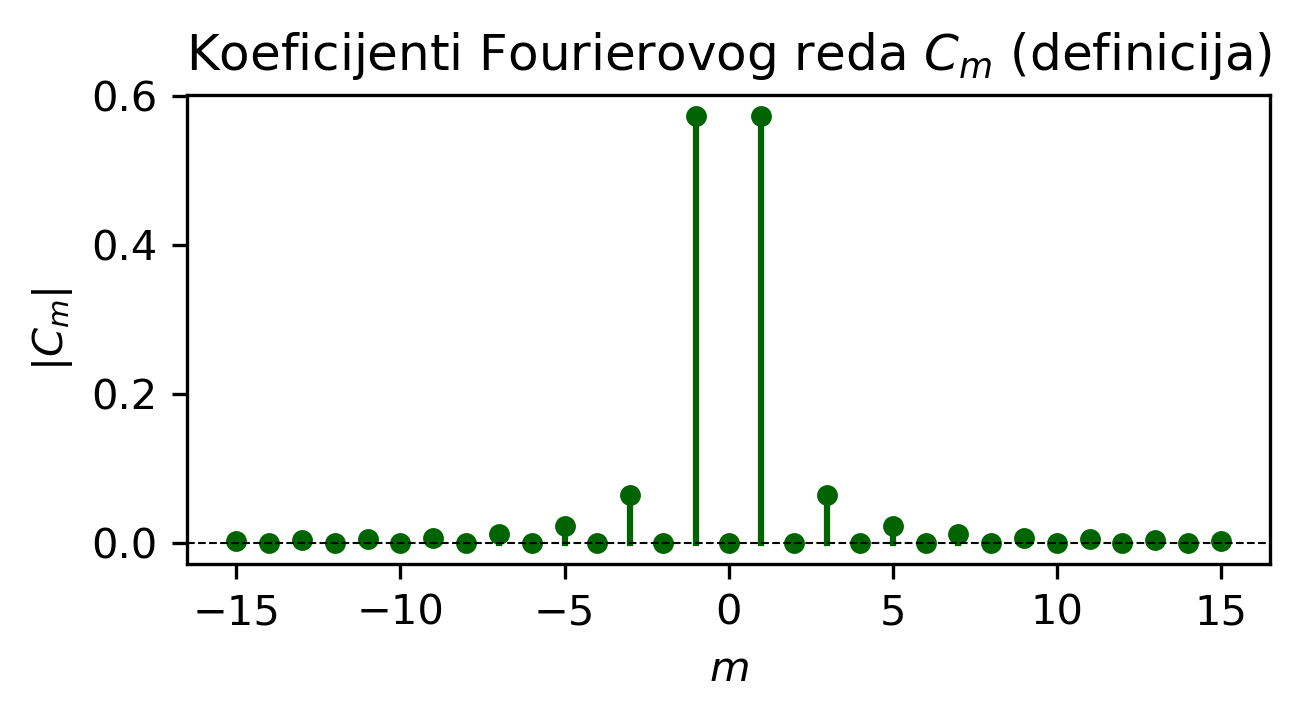

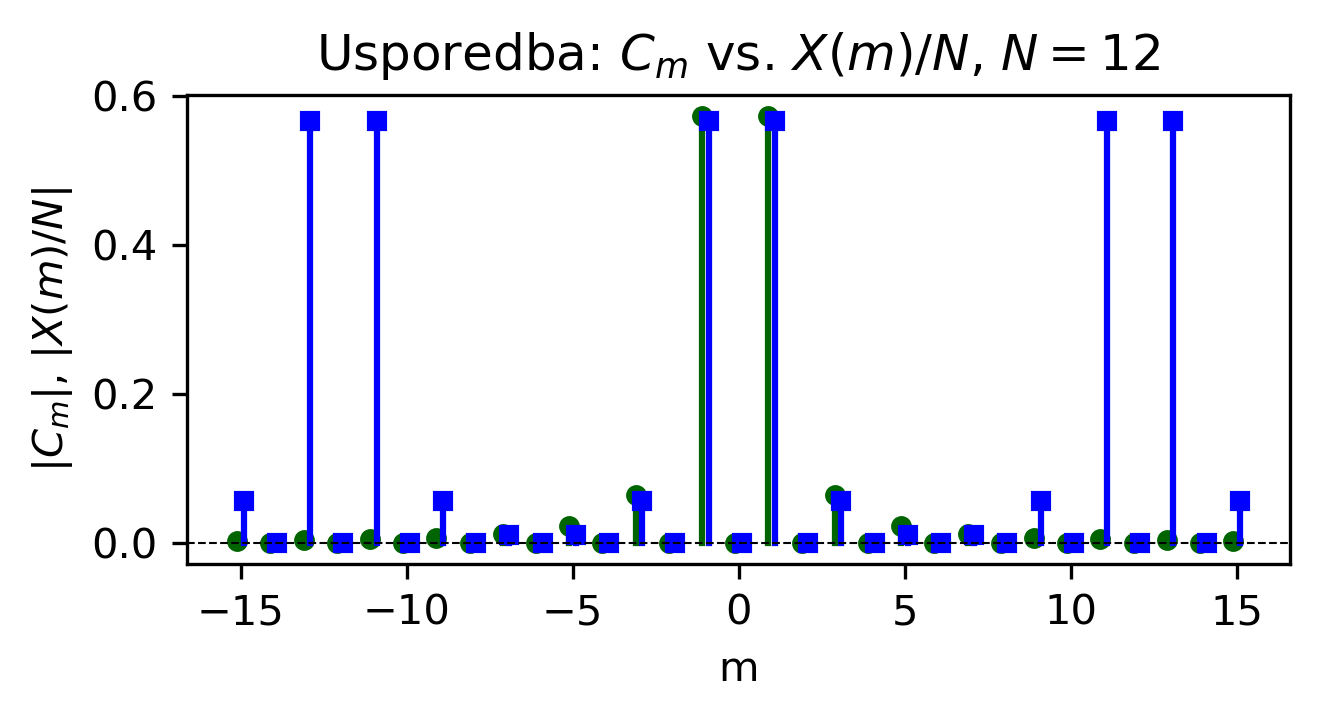

In [7]:
sis.dijagram(m_os, np.abs(C_def), tip='uzorci',
         x_labela='$m$',y_labela='$|C_m|$',
         naslov='Koeficijenti Fourierovog reda $C_m$ (definicija)')


sis.dijagram(serije=[dict(t=m_os-0.1, x=np.abs(C_def), tip='uzorci'),
                 dict(t=m_os+0.1, x=np.abs(C_dft), tip='uzorci', 
                      stil='b', marker='s')], x_labela='m', 
                 y_labela='$|C_m|$, $|X(m)/N|$',              
                 naslov=f'Usporedba: $C_m$ vs. $X(m)/N$, $N={N}$')
 

In [8]:
# =========================================================
# Kod 8.3 - Priblizno odredjivanje uzoraka spektra
#           kontinualne funkcije pomocu DFT
# =========================================================

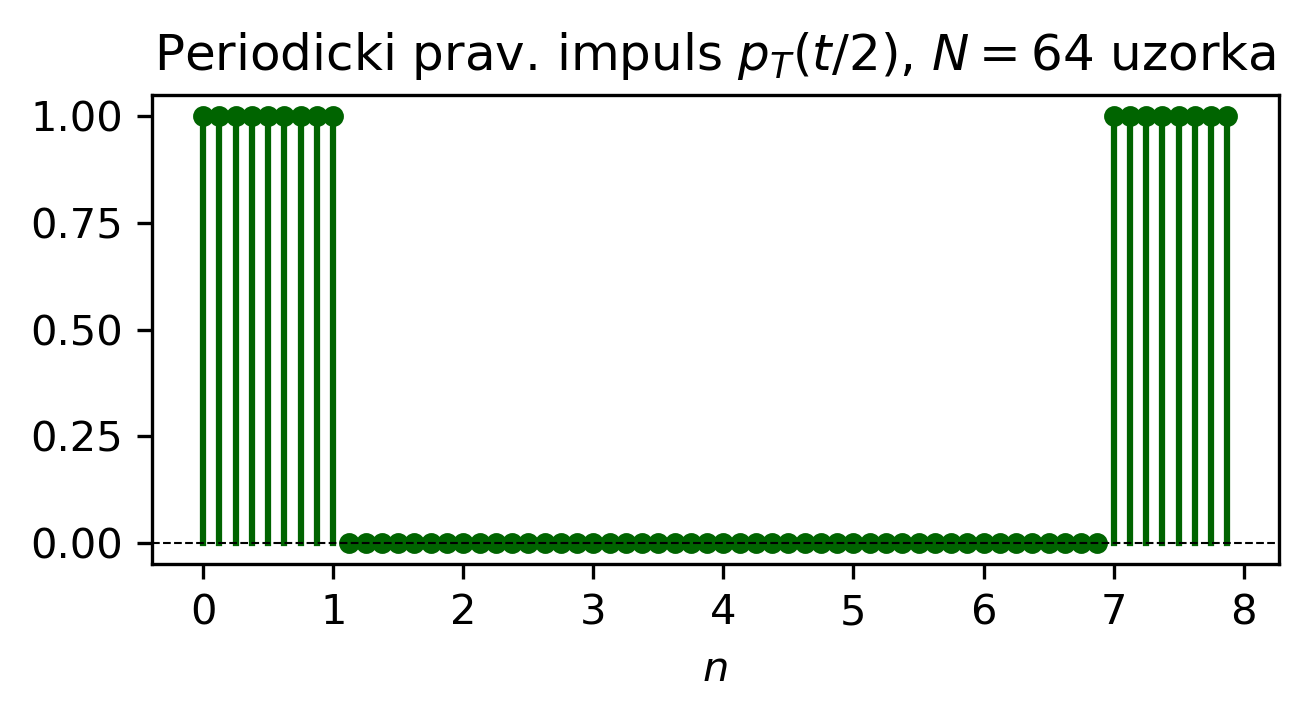

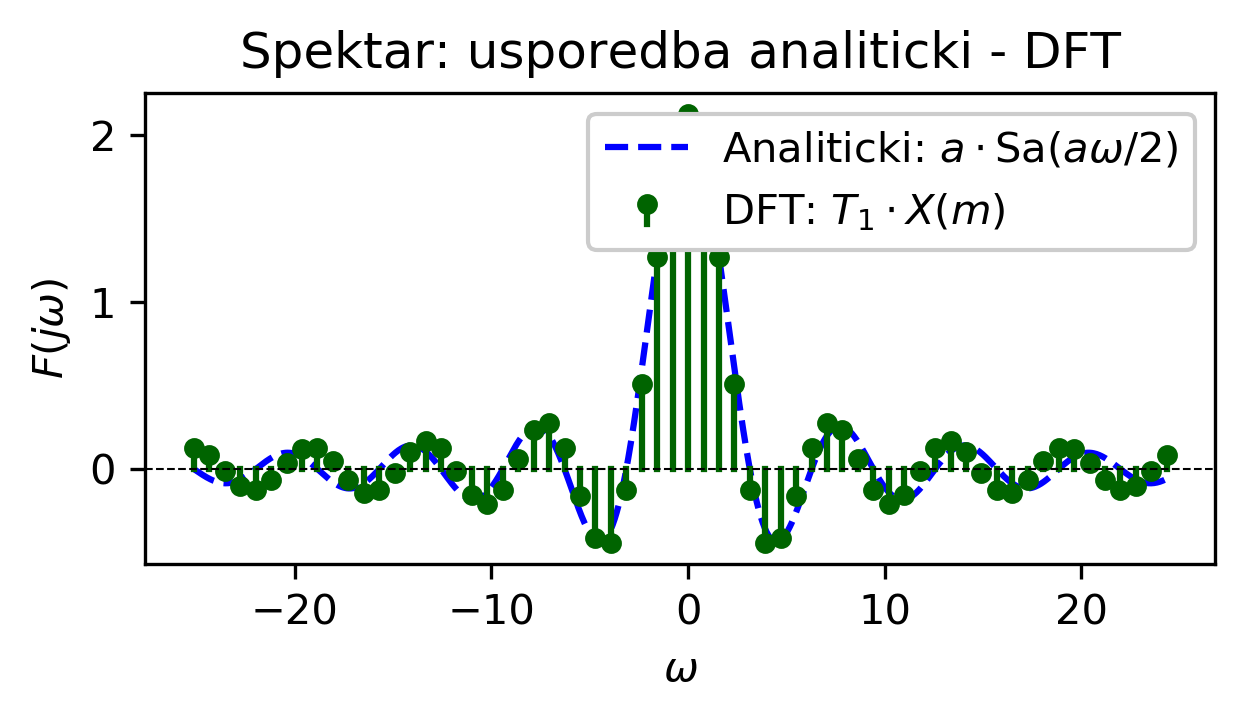

In [9]:
# parametri
a  = 2      # sirina pravougaonog impulsa
T0 = 8      # interval posmatranja
N  = 64     # broj uzoraka
T1 = T0 / N        # period uzorkovanja
w0 = 2 * np.pi / T0   # frekventni korak

# vremenska baza [0, T0) - impuls smjesten na pocetak
t1 = np.arange(N) * T1
x1 = np.where((t1 <= a/2) | (t1 >= T0 - a/2), 1.0, 0.0)

# DFT i aproksimacija spektra: F(jmw0) ~= T1 * X(m)
X    = sis.fft(x1)
X_sh = sis.fftshift(X)
m_os = np.arange(-N // 2, N // 2)
w_os = m_os * w0
F_dft = T1 * X_sh

# gusta frekventna osa za analiticki spektar
w_cont = np.linspace(w_os[0], w_os[-1], 1000)
F_def  = a * np.sinc(a * w_cont / (2 * np.pi))

sis.dijagram(t1, x1, tip='uzorci', 
         naslov=f'Periodicki prav. impuls $p_T(t/{a})$, $N={N}$ uzorka')
  
    
sis.dijagram(serije=[
             dict(t=w_cont, x=F_def, stil='b--', oznaka=
                  r'Analiticki: $a \cdot \mathrm{Sa}(a\omega/2)$'),
             dict(t=w_os, x=np.real(F_dft), tip='uzorci',
                  marker = 'o', oznaka=r'DFT: $T_1 \cdot X(m)$'),
             ],
             x_labela=r'$\omega$', y_labela=r'$F(j\omega)$',
             naslov='Spektar: usporedba analiticki - DFT')
 

In [10]:
# =========================================================
# Kod 8.4 - Konvolucija dvije sekvence pomocu DFT
# =========================================================

In [11]:
# definiranje sekvenci
f = np.array([1, 1, 1, 1])     # f[n], n = 0,1,2,3
h = np.array([1, 1, -1, -1])   # h[n], n = 0,1,2,3
N = len(f)                     # duzina sekvenci N=4

# a) linearna konvolucija - direktno
g_lin = np.convolve(f, h)      # rezultat ima 2N-1 = 7 clanova

# b) periodicka konvolucija preko FFT (zero-padding na 2N)
f_pad = np.zeros(2 * N); f_pad[:N] = f
h_pad = np.zeros(2 * N); h_pad[:N] = h

F = sis.fft(f_pad)             # DFT prosirenih sekvenci
H = sis.fft(h_pad)
G = F * H                      # mnozenje u frekventnom domenu
g_per = np.real(sis.ifft(G))   # inverzna DFT

print("Linearna konvolucija (np.convolve):")
print(f"  g[n] = {g_lin}")
print()
print("Periodicka konvolucija via FFT (2N tacaka):")
print(f"  g[n] = {np.round(g_per, 4)}")

Linearna konvolucija (np.convolve):
  g[n] = [ 1  2  1  0 -1 -2 -1]

Periodicka konvolucija via FFT (2N tacaka):
  g[n] = [ 1.  2.  1.  0. -1. -2. -1.  0.]


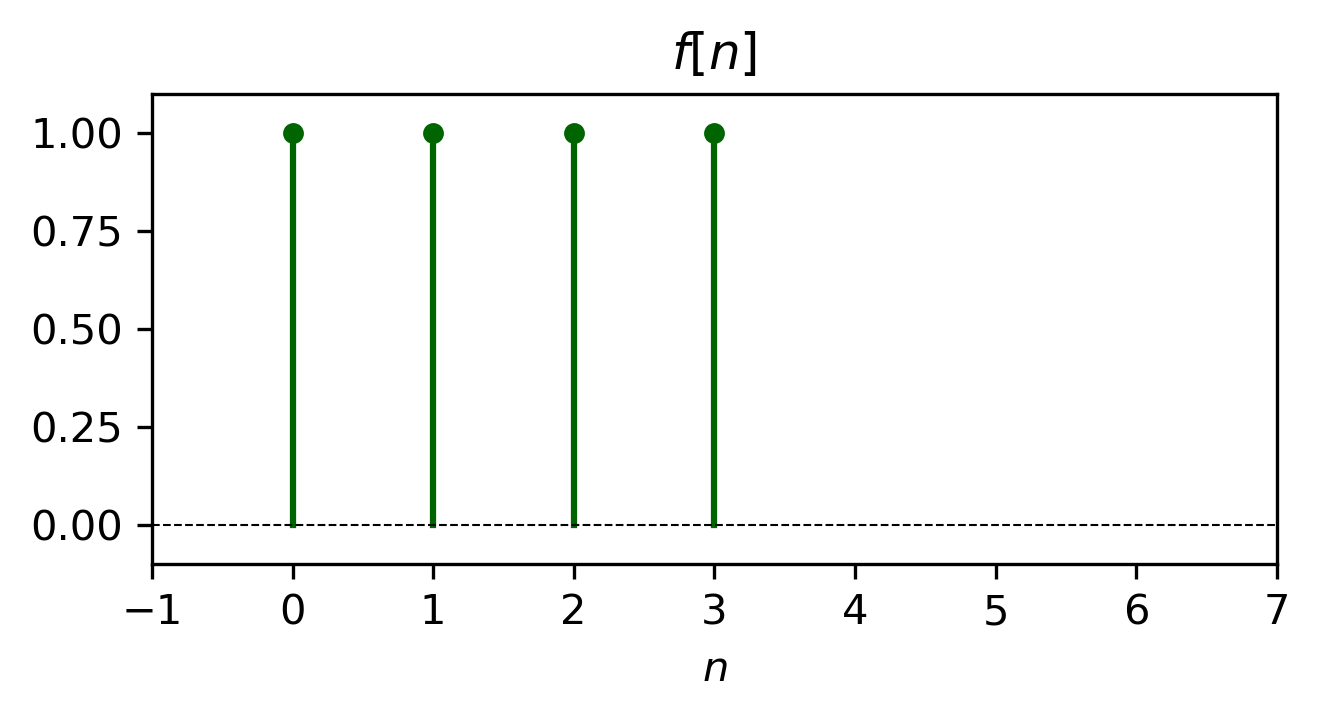

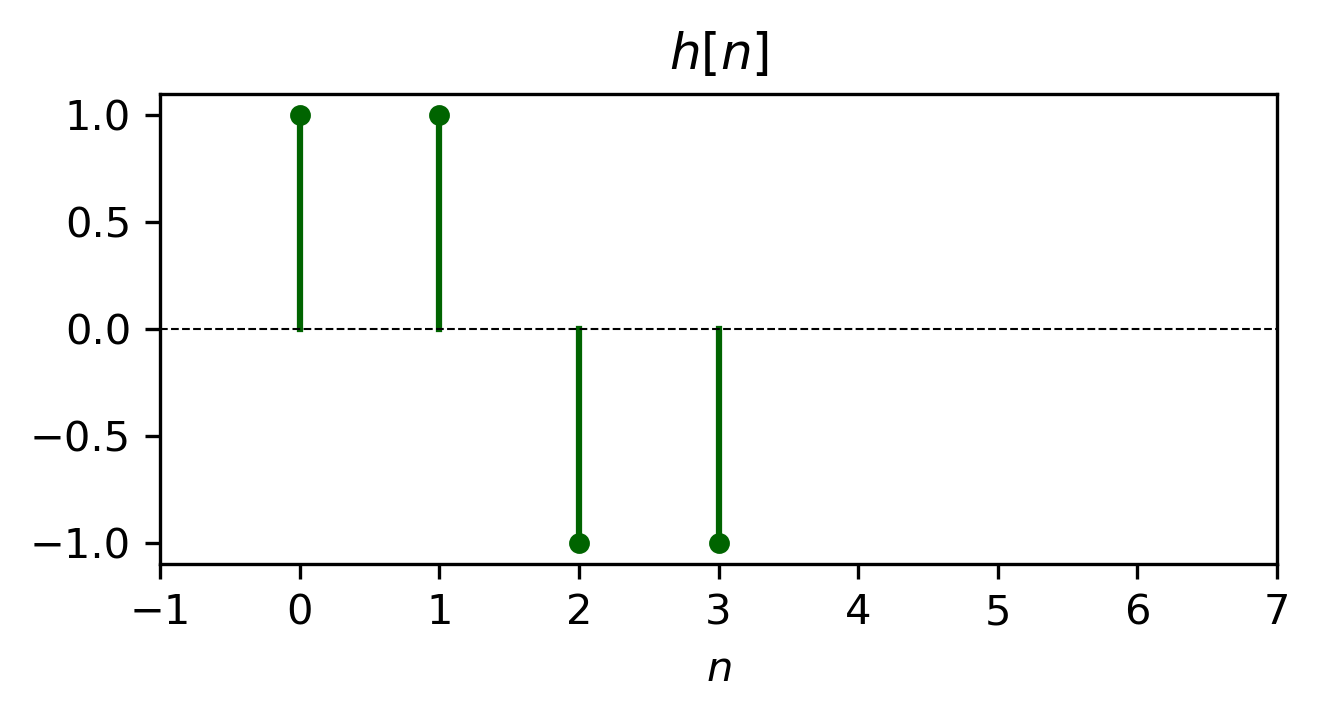

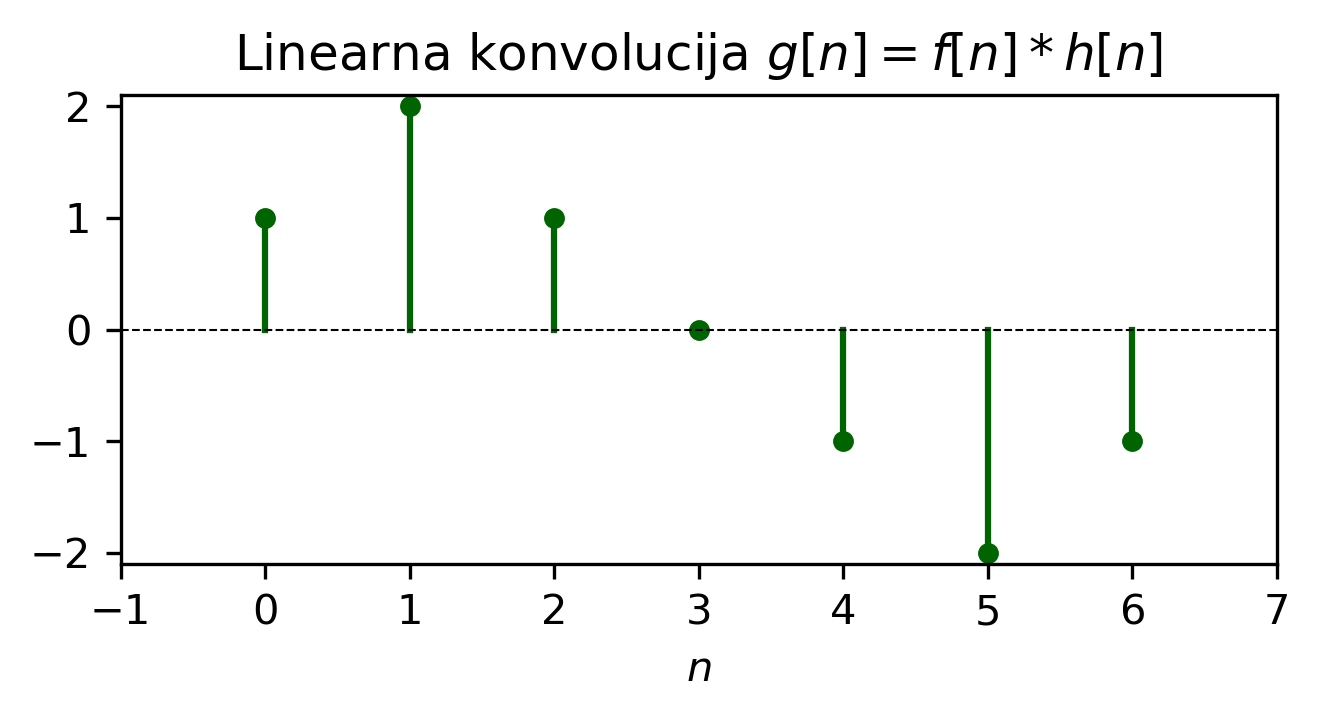

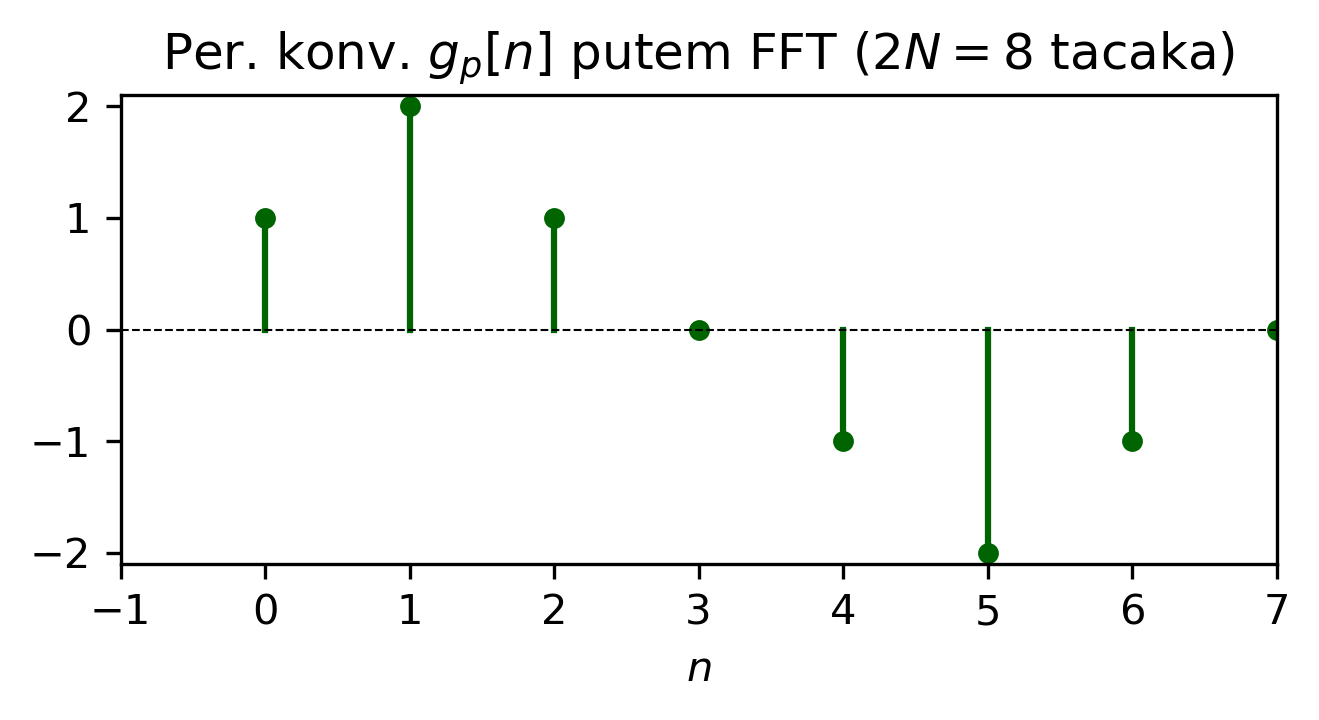

In [12]:
n_lin = np.arange(len(g_lin))
n_per = np.arange(2 * N)
xt = range(2 * N)
xl = (-0.5, 2*N - 0.5)

sis.dijagram(np.arange(N), f, tip='uzorci',
             xlim=[-1,7],ylim=[-0.1,1.1],
             naslov='$f[n]$')

sis.dijagram(np.arange(N), h, tip='uzorci',             
             xlim=[-1,7],ylim=[-1.1,1.1],
             naslov='$h[n]$')

sis.dijagram(n_lin, g_lin, tip='uzorci',               
             xlim=[-1,7],ylim=[-2.1,2.1],
             naslov='Linearna konvolucija $g[n] = f[n] * h[n]$')

sis.dijagram(n_per, g_per, tip='uzorci',              
             xlim=[-1,7],ylim=[-2.1,2.1],
             naslov=f'Per. konv. $g_p[n]$ putem FFT ($2N={2*N}$ tacaka)')